# Lecture 1: What an LLM actually does

**Core message:** an LLM is a function from text to a probability distribution over the next token.
Everything else is repeated sampling, plus training that shapes the distribution.

Three models:

| Name here | Model | Runs | What it is |
| --- | --- | --- | --- |
| `base` | OLMo 2 1B | locally | Only pretrained: it continues text |
| `aligned` | OLMo 2 1B Instruct | locally | The same model after post-training (SFT, DPO, RL) |
| `API_MODEL` | Qwen3 30B-A3B Instruct | GWDG SAIA API | A capable current instruct model |

`base` and `aligned` share tokenizer and pretraining, so every difference between them comes from post-training.
The API model needs a personal SAIA key in the environment variable `SAIA_API_KEY`.

## Setup

In [1]:
import html, math, os, time
import torch
import matplotlib.pyplot as plt
from IPython.display import HTML
from openai import OpenAI
from transformers import AutoTokenizer, AutoModelForCausalLM

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

def load(name):
    model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16).to(DEVICE)
    model.tok = AutoTokenizer.from_pretrained(name)  # each model has its own tokenizer
    return model

base = load("allenai/OLMo-2-0425-1B")
aligned = load("allenai/OLMo-2-0425-1B-Instruct")

API_MODEL = "qwen3-30b-a3b-instruct-2507"
client = OpenAI(api_key=os.environ["SAIA_API_KEY"], base_url="https://chat-ai.academiccloud.de/v1")
api_tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-30B-A3B-Instruct-2507")  # the API model's tokenizer only, no weights
print(DEVICE)

/Users/trettin/work/teaching/agentic_coding/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1102 16:51:18.092000 84178 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

Loading weights:   1%|          | 1/179 [00:01<04:26,  1.50s/it]

Loading weights:  39%|███▊      | 69/179 [00:01<00:02, 51.96it/s]

Loading weights:  47%|████▋     | 84/179 [00:02<00:01, 51.50it/s]

... (8 outputs left out)

Loading weights: 100%|██████████| 179/179 [00:03<00:00, 46.06it/s]

Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 179/179 [00:00<00:00, 6669.93it/s]

mps


In [2]:
def encode(model, text):
    return model.tok(text, return_tensors="pt", add_special_tokens=False).input_ids.to(DEVICE)

@torch.no_grad()
def next_token_probs(model, text):
    """The model's whole output: one probability for every token in the vocabulary."""
    return model(encode(model, text)).logits[0, -1].float().softmax(-1)

def show_top(model, text, k=10):
    p, ids = next_token_probs(model, text).topk(k)
    for pi, i in zip(p.tolist(), ids.tolist()):
        print(f"{pi:6.1%}  {'█' * round(pi * 50):<50} {model.tok.decode(i)!r}")

@torch.no_grad()
def complete(model, text, max_new_tokens=60, temperature=0.0, top_p=1.0, seed=None):
    """Raw text continuation. temperature=0 means greedy: always take the most likely token."""
    if seed is not None:
        torch.manual_seed(seed)
    ids = encode(model, text)
    sampling = dict(do_sample=True, temperature=temperature, top_p=top_p, top_k=0) if temperature > 0 else dict(do_sample=False)
    out = model.generate(ids, max_new_tokens=max_new_tokens, pad_token_id=model.tok.eos_token_id, **sampling)
    return model.tok.decode(out[0, ids.shape[1]:])

def chat_prompt(tok, user, system=None):
    """The text document the harness builds from a conversation."""
    messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": user}]
    return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

def chat(model, user, **kw):
    reply = complete(model, chat_prompt(model.tok, user), **kw)
    return reply.split("<|endoftext|>")[0]  # cut at the end-of-turn token

last_request = 0.0

def api(endpoint, **kw):
    """One request to the API model. SAIA allows 2 requests per 10 s per key, so we wait 5 s between requests."""
    global last_request
    time.sleep(max(0, last_request + 5 - time.time()))
    last_request = time.time()
    return endpoint.create(model=API_MODEL, **kw)

def ask(user, max_tokens=300, temperature=0.0, **kw):
    """Chat with the API model. The server applies the chat template."""
    r = api(client.chat.completions, messages=[{"role": "user", "content": user}],
            max_tokens=max_tokens, temperature=temperature, **kw)
    return r.choices[0].message.content

## 1. Hook: fluent is not the same as correct (0–10 min)

`scipy.integrate.solve_ivp` is a real function. It has no parameter called `tolerance_mode`.

In [3]:
print(ask("What does the tolerance_mode argument of scipy.integrate.solve_ivp do?"))

The `tolerance_mode` argument in `scipy.integrate.solve_ivp` controls **how the relative and absolute tolerances are interpreted** when determining the error estimates during the integration of an ODE (ordinary differential equation).

### Key Points:

- **Purpose**: It determines whether the error tolerance is applied **component-wise** (per state variable) or **globally** (on the entire solution vector).
- **Available options**:
  - `'abs'` (default): The absolute tolerance is applied **independently** to each component of the solution vector.
  - `'rel'`: The relative tolerance is applied **independently** to each component.
  - `'mixed'`: Uses a **mixed** approach where the error is estimated using a combination of relative and absolute tolerances per component.

### Detailed Explanation:

The solver estimates the local error as:

```
error ≈ |y_i - y_i^true| / (atol + rtol * |y_i|)
```

- `y_i` is the i-th component of the solution.
- `atol` = absolute tolerance
- `rtol` = relativ

Fluent, well formatted, plausible, and invented. By the end of this lecture we can say *why*.

Models of this size usually notice a function that does not exist at all (try `numpy.linalg.robust_solve`).
A plausible parameter of a real function is much harder to notice, and it is exactly the kind of error that ends up in generated code.

## 2. Tokens (10–25 min)

The model never sees letters or words, only a sequence of integer token IDs.

In [4]:
def show_tokens(tok, text):
    ids = tok(text, add_special_tokens=False).input_ids
    print(f"{len(text)} characters -> {len(ids)} tokens")
    print(" | ".join(tok.decode(i) for i in ids))
    print(ids, "\n")

for text in [
    "The quick brown fox jumps over the lazy dog.",
    "Donaudampfschifffahrtsgesellschaftskapitän",
    "def add(a, b):\n    return a + b",
    "1234567 * 7654321 = 9449772114007",
]:
    show_tokens(api_tok, text)

44 characters -> 10 tokens
The |  quick |  brown |  fox |  jumps |  over |  the |  lazy |  dog | .
[785, 3974, 13876, 38835, 34208, 916, 279, 15678, 5562, 13] 

42 characters -> 17 tokens
D | ona | ud | amp | fs | ch | if | ff | ah | rt | sg | es | ellschaft | sk | ap | it | än
[35, 6721, 661, 1121, 3848, 331, 333, 542, 1466, 3342, 1991, 288, 69701, 4886, 391, 275, 15141] 

31 characters -> 11 tokens
def |  add | (a | , |  b | ):
 |     |  return |  a |  + |  b
[750, 912, 2877, 11, 293, 982, 262, 470, 264, 488, 293] 

33 characters -> 31 tokens
1 | 2 | 3 | 4 | 5 | 6 | 7 |  * |   | 7 | 6 | 5 | 4 | 3 | 2 | 1 |  = |   | 9 | 4 | 4 | 9 | 7 | 7 | 2 | 1 | 1 | 4 | 0 | 0 | 7
[16, 17, 18, 19, 20, 21, 22, 353, 220, 22, 21, 20, 19, 18, 17, 16, 284, 220, 24, 19, 19, 24, 22, 22, 17, 16, 16, 19, 15, 15, 22] 



Token IDs belong to one model. OLMo uses a different vocabulary, so the same text gets different IDs and pieces:

In [5]:
for name, tok in [("OLMo 2", base.tok), ("Qwen3", api_tok)]:
    print(f"{name}: vocabulary of {len(tok):,} tokens")
    show_tokens(tok, "1234567 * 7654321 = 9449772114007")

OLMo 2: vocabulary of 100,278 tokens
33 characters -> 15 tokens
123 | 456 | 7 |  * |   | 765 | 432 | 1 |  = |   | 944 | 977 | 211 | 400 | 7
[4513, 10961, 22, 353, 220, 22240, 16739, 16, 284, 220, 25687, 26409, 11483, 3443, 22] 

Qwen3: vocabulary of 151,669 tokens
33 characters -> 31 tokens
1 | 2 | 3 | 4 | 5 | 6 | 7 |  * |   | 7 | 6 | 5 | 4 | 3 | 2 | 1 |  = |   | 9 | 4 | 4 | 9 | 7 | 7 | 2 | 1 | 1 | 4 | 0 | 0 | 7
[16, 17, 18, 19, 20, 21, 22, 353, 220, 22, 21, 20, 19, 18, 17, 16, 284, 220, 24, 19, 19, 24, 22, 22, 17, 16, 16, 19, 15, 15, 22] 



The compound arrives as a handful of opaque pieces. To count the letter *s*, the model would have to
have learned how each piece is spelled:

In [6]:
word = "Donaudampfschifffahrtsgesellschaftskapitän"
print(ask(f"How many times does the letter s occur in the word {word}? Answer with a number only."))
print("correct:", word.count("s"))

11
correct: 5


The famous "strawberry" test: inside a sentence, ` strawberry` is a single token for both tokenizers.

In [7]:
show_tokens(base.tok, "How many r's are in the word strawberry?")
for q in ["How many times does the letter r occur in the word strawberry? Answer with a number only.",
          "How many r's are in the word strawberry?"]:
    print(q, "->", chat(aligned, q, max_new_tokens=30))

40 characters -> 10 tokens
How |  many |  r | 's |  are |  in |  the |  word |  strawberry | ?
[4438, 1690, 436, 596, 527, 304, 279, 3492, 73700, 30] 



How many times does the letter r occur in the word strawberry? Answer with a number only. -> The letter 'r' appears 3 times in the word 'strawberry'.


How many r's are in the word strawberry? -> There are 2 'r's' in the word 'strawberry'.


The same question in different words gets a different answer (3 is right). The model is not counting; it continues the text in a likely way.
Large models like the API model have seen this exact question so often that they now get it right, which is why the compound above is the better test for them.

## 3. The next-token distribution and sampling (25–45 min)

One forward pass gives one probability for each token in the vocabulary. That distribution is the model's *only* output.

In [8]:
show_top(base, "The capital of Australia is")

 72.0%  ████████████████████████████████████               ' Canberra'
  4.5%  ██                                                 ' Sydney'
  3.2%  ██                                                 ' the'
  2.0%  █                                                  ' called'
  1.4%  █                                                  ' Melbourne'
  1.2%  █                                                  ' known'
  1.0%                                                     ' a'
  0.9%                                                     ' Darwin'
  0.7%                                                     ' in'
  0.7%                                                     ' Perth'


Generation is a loop: pick a token from the distribution, append it, run the model again.
Written out by hand:

In [9]:
@torch.no_grad()
def generate_by_hand(model, text, steps=15, temperature=1.0, seed=1):
    torch.manual_seed(seed)
    ids = encode(model, text)
    for _ in range(steps):
        logits = model(ids).logits[0, -1].float()
        probs = (logits / temperature).softmax(-1)
        next_id = torch.multinomial(probs, 1)
        print(f"{model.tok.decode(next_id)!r:>16}  p = {probs[next_id].item():.1%}")
        ids = torch.cat([ids, next_id[None]], dim=1)
    return model.tok.decode(ids[0])

print(generate_by_hand(base, "The capital of Australia is"))

     ' Canberra'  p = 72.0%
             '.'  p = 28.3%
          ' The'  p = 19.7%
        ' Great'  p = 0.2%


      ' Barrier'  p = 90.9%
         ' Reef'  p = 98.6%


           ' of'  p = 2.6%
    ' Australia'  p = 56.4%
           ' is'  p = 77.7%


          ' the'  p = 80.4%


        ' world'  p = 72.6%
            "'s"  p = 78.8%
      ' largest'  p = 90.4%


        ' coral'  p = 84.6%


         ' reef'  p = 98.6%
The capital of Australia is Canberra. The Great Barrier Reef of Australia is the world's largest coral reef


Each run of the loop draws a different path. Once an unlikely token is drawn, it becomes part of the text and
conditions everything after it. Try a few seeds.

**Temperature** divides the logits before the softmax. Low temperature sharpens the distribution
(nearly always the top token), high temperature flattens it (rare tokens get picked).

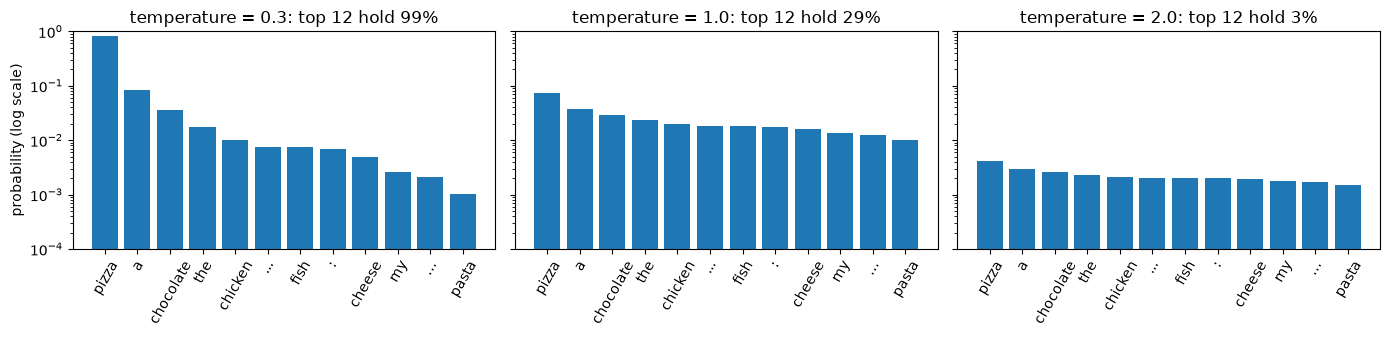

In [10]:
logits = base(encode(base, "My favourite food is")).logits[0, -1].float().detach()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, T in zip(axes, [0.3, 1.0, 2.0]):
    probs = (logits / T).softmax(-1)
    p, ids = probs.topk(12)
    ax.bar([base.tok.decode(i) for i in ids.tolist()], p.cpu())
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1)
    ax.set_title(f"temperature = {T}: top 12 hold {p.sum():.0%}")
    ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("probability (log scale)")
plt.tight_layout()

In [11]:
prompt = "Once upon a time, in a small village in the Alps,"
for T in [0.0, 0.7, 1.5]:
    print(f"--- temperature {T}")
    for seed in [1, 2]:
        print(repr(complete(base, prompt, max_new_tokens=30, temperature=T, seed=seed)))

--- temperature 0.0


' there lived a wise old man named Grandfather. He had a beautiful garden where he grew all sorts of flowers. One day, he decided to plant'


' there lived a wise old man named Grandfather. He had a beautiful garden where he grew all sorts of flowers. One day, he decided to plant'
--- temperature 0.7


' lived a young girl named Amelie. She had a secret wish - to become a fairy tale princess.\n\nOne day, while walking through the forest'


' lived a family of four: a mother, a father, and their two children - a boy and a girl. Their home was humble and beautiful,'
--- temperature 1.5


' Team Russell talked Male, Arnold party crashers and mean kan []\'gyss betting Josef bedroom-fister accident oppon./ tells Maria Bluzz` "\\'


' lived a small Ghitor-Legovarcor raised by kind Czechosolgay (goose food/filter stations near common teenage riffraffe problem Sol'


Temperature 0 is repeatable. Higher temperature gives variety, and at 1.5 the text falls apart.
**top-p** (nucleus sampling) is the other common knob: it samples only from the smallest set of tokens
whose probabilities add up to p, which cuts off the long tail of unlikely tokens.

In [12]:
for p in [1.0, 0.9, 0.5]:
    print(f"top_p={p}:", repr(complete(base, prompt, max_new_tokens=30, temperature=1.5, top_p=p, seed=1)))

top_p=1.0: ' Team Russell talked Male, Arnold party crashers and mean kan []\'gyss betting Josef bedroom-fister accident oppon./ tells Maria Bluzz` "\\'


top_p=0.9: ' Team Russell talked sometimes, relied party crashers and mean houses too hunggy tape betting Josef bedroom Euroidea accident dull Chronicle tells Maria Bluzzentected'


top_p=0.5: ' lived two young men, Arnold Schmidt and Marcus Freitag. They were best friends who loved skiing and snowboarding more than anything else. One day,'


## 4. Confidently wrong (45–55 min)

High probability means "typical text", not "true". We colour each answer token by the probability the model gave it.

In [13]:
def show_confidence(user, max_tokens=60):
    """The API returns, for each generated token, its log-probability and the top alternatives."""
    r = api(client.chat.completions, messages=[{"role": "user", "content": user}], max_tokens=max_tokens,
            temperature=0, logprobs=True, top_logprobs=3)
    spans = []
    for t in r.choices[0].logprobs.content:
        if t.token == "<|im_end|>":
            break
        p = math.exp(t.logprob)
        alts = ", ".join(f"{a.token!r} {math.exp(a.logprob):.0%}" for a in t.top_logprobs)
        spans.append(f'<span title="{html.escape(alts)}" style="background: hsl({120 * p:.0f}, 80%, 80%); color: black">{html.escape(t.token)}</span>')
    return HTML("<div style='line-height: 1.8'>" + "".join(spans) + "</div>"
                "<small>green = high probability, red = low. Hover for the top 3 alternatives.</small>")

show_confidence("In which year was the Technical University of Munich founded? Answer in one sentence.")

In [14]:
show_confidence("Who was the doctoral advisor of Rudolf Mössbauer? Answer in one sentence.")

Correct answers: TUM was founded in **1868**. Mössbauer did his doctorate at TUM under **Heinz Maier-Leibnitz**.
The model hesitates once, at the first name. Once "Wolfgang" is drawn, "Pauli" follows with near certainty:
each token conditions the next.

The model has no stored fact to look up, only a likely continuation. Ask the same question five times
(`n=5` returns five samples in one request):

In [15]:
r = api(client.chat.completions, n=5, max_tokens=20, temperature=1.0,
        messages=[{"role": "user", "content": "Who was the doctoral advisor of Rudolf Mössbauer? Answer with the name only."}])
for choice in r.choices:
    print(choice.message.content)

Albert Einstein
Wolfgang Pauli
Arnold Sommerfeld
Walter Gerlach
Arnold Sommerfeld


## 5. Prompting as conditioning (55–70 min)

A prompt does not "instruct" a base model. It changes which continuations are likely.
The format of the text decides what comes next.

In [16]:
article = """The IceCube Neutrino Observatory is a particle detector buried in the Antarctic ice at the South Pole. \
More than five thousand light sensors hang on long cables between 1450 and 2450 metres below the surface, \
filling about one cubic kilometre of ice. When a high-energy neutrino interacts in or near the detector, \
it produces charged particles that emit faint blue Cherenkov light. The sensors record this light, and \
from its timing and brightness physicists reconstruct the neutrino's direction and energy. In 2013 IceCube \
reported the first evidence for high-energy neutrinos from outside the solar system."""

for ending in ["\n\n", "\n\nTL;DR:"]:
    print(f"--- article + {ending!r}")
    print(complete(base, article + ending, max_new_tokens=60), "\n")

--- article + '\n\n'


The IceCube Neutrino Observatory is a particle detector buried in the Antarctic ice at the South Pole. More than five thousand light sensors hang on long cables between 1450 and 2450 metres below the surface, filling about one cubic kilometre of ice. When a high-energy neutrino interacts 

--- article + '\n\nTL;DR:'


 The IceCube Neutrino Observatory is a particle detector buried in the Antarctic ice at the South Pole. It is the world's largest neutrino observatory, and the first to detect high-energy neutrinos from outside the solar system.<|endoftext|> 



With nothing after it, the article simply goes on. "TL;DR:" is followed by a summary on the web,
so a summary becomes the likely continuation.

In [17]:
few_shot = """Q: What is the chemical symbol for gold?
A: Au

Q: How many legs does a spider have?
A: 8

Q: What is the boiling point of water at sea level in Celsius?
A:"""
print(complete(base, few_shot, max_new_tokens=30))

 100

Q: What is the capital of the United States?
A: Washington, D.C.

Q: What is the capital of the United


The few-shot format makes a short answer likely, and the model then goes on to write the next Q/A pair:
nothing tells it to stop. A harness would cut the text at the next `Q:`.

In [18]:
show_top(base, "English: cheese\nGerman: Käse\n\nEnglish: butterfly\nGerman:")

 21.1%  ███████████                                        ' Sch'
 12.8%  ██████                                             ' Bl'
 11.3%  ██████                                             ' Fl'
  2.7%  █                                                  ' Butter'
  2.5%  █                                                  ' Pap'
  1.7%  █                                                  ' B'
  1.5%  █                                                  ' H'
  1.5%  █                                                  ' Br'
  1.5%  █                                                  ' Fle'
  1.0%  █                                                  ' Butterfly'


## 6. Alignment (70–85 min)

The same direct instruction to the base model (as plain text) and to the aligned model (through its chat template):

In [19]:
instruction = "Write a haiku about neutrinos."
print("--- base:")
print(complete(base, instruction, max_new_tokens=60))
print("\n--- aligned:")
print(chat(aligned, instruction, max_new_tokens=60))

--- base:


 

Neutrinos are tiny particles that travel through space. They are so small that they can pass through anything, including the Earth. They are so small that they can pass through anything, including the Earth. They are so small that they can pass through anything, including the Earth. They are

--- aligned:


Neutrinos pass through
The universe without a trace
A ghostly whisper


What does the aligned model actually see? The "conversation" is one text document,
assembled by the harness with special marker tokens:

In [20]:
print(chat_prompt(aligned.tok, instruction, system="You are a helpful assistant."))

<|endoftext|><|system|>
You are a helpful assistant.
<|user|>
Write a haiku about neutrinos.
<|assistant|>



Each model family has its own template. When we call the chat endpoint of the API, the server builds this document for the Qwen model:

In [21]:
print(chat_prompt(api_tok, instruction, system="You are a helpful assistant."))

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Write a haiku about neutrinos.<|im_end|>
<|im_start|>assistant



The aligned model is still a next-token predictor. It was trained on many documents of exactly this shape,
so after `<|assistant|>` it predicts an assistant's reply. Without the template, it just continues the text:

In [22]:
print(complete(aligned, "The capital of Australia is", max_new_tokens=40))

 Canberra, and it is located in the northern part of the country. Canberra was chosen as the capital in 1908 because it was seen as a compromise location between the capital cities of Sydney and Melbourne


The same holds for the 30B model. The API's raw `/completions` endpoint sends our text to the model without any template:

In [23]:
r = api(client.completions, prompt="The capital of Australia is", max_tokens=50, temperature=0)
print(r.choices[0].text)

 Canberra. The capital of the United States is Washington, D.C. The capital of the United Kingdom is London. The capital of Canada is Ottawa. The capital of Germany is Berlin. The capital of France is Paris. The capital of Japan is Tokyo


Without the markers, the large instruct model behaves like a base model and continues the pattern.

The base model has no chat template at all: `base.tok.chat_template` is `None`. If we hand it the aligned model's
document, it does not answer, because it never learned what the markers mean:

In [24]:
print(complete(base, chat_prompt(aligned.tok, instruction), max_new_tokens=60))

Neutrinos are the most common particles in the universe.
<|user|>
Neutrinos are the most common particles in the universe.
<|user|>
Neutrinos are the most common particles in the universe.
<|user|>
Neutrinos are the most common particles in


Instruction following is learned behaviour, not understanding: the same mechanism with a differently shaped distribution.

> Note: many recent "base" models were pretrained on large amounts of synthetic chat data. Qwen3.5-2B-Base, for example,
> answers "Write a haiku about neutrinos." by opening a `<think>` block and reasoning like an assistant.
> That's why we use OLMo 2 here: its base model still behaves like a text continuer, and its training data is fully published.

## Wrap-up (85–90 min)

- An LLM outputs a probability distribution over the next token; text comes from sampling it in a loop.
- Probability measures "typical", not "true". Fluent wrong answers are the expected failure mode.
- A prompt conditions the distribution. Post-training makes "answer the instruction" the likely continuation.
- A chat is one text document that a program (the *harness*) builds and the model continues.

**Next lecture:** the model can't multiply 7-digit numbers reliably. What if it could ask a program for help?

In [25]:
print(ask("What is 1234567 * 7654321? Answer with the number only."))
print("correct:", 1234567 * 7654321)

9449999999999
correct: 9449772114007
